# Лабораторная работа 7. Анализ устойчивости ML-моделей в чёрно-ящичном сценарии

### Transfer-based, score-based и decision-based подходы

**Курс:** Машинное обучение. Безопасность ИИ-систем

**По материалам лекции 5**


**Вариант / seed:** _номер варианта или значение SEED_

> Работа выполняется только на предоставленной синтетической модели. Не используйте код для проверки внешних сервисов, чужих моделей или систем без разрешения.

## 1. Цель работы

Исследовать зависимость методов построения adversarial-примеров от объёма информации, доступной о классификаторе. Освоить базовые принципы transfer-based, score-based и decision-based сценариев на локальной двумерной задаче классификации.

## 2. Задачи

1. Сформировать синтетический набор данных и обучить target-модель.
2. Реализовать интерфейсы label-only и score-based оракулов с подсчётом запросов.
3. Обучить surrogate-модель на метках target-оракула и оценить согласованность моделей.
4. Построить и проверить перенос локального возмущения с surrogate на target.
5. Сравнить ZOO и NES по направлению оценки и числу запросов.
6. Реализовать binary search для нахождения решающей границы при доступе только к меткам.
7. Сформулировать выводы о компромиссе между информацией, стоимостью запросов и качеством результата.

## 3. Краткая теория

| Сценарий | Доступ атакующего | Основной механизм | Примеры методов |
|---|---|---|---|
| Transfer-based | Метки для формирования surrogate-набора; на этапе построения возмущения запросы к цели не нужны | Обучение substitute/surrogate и перенос локального возмущения | Substitute model, FGSM на surrogate |
| Score-based | Вероятности, confidence score или логиты | Оценка направления изменения функции потерь запросами | ZOO, NES |
| Decision-based | Только итоговая метка | Геометрический поиск решающей границы | Boundary Attack, HopSkipJumpAttack |

В этой работе все эксперименты выполняются в двумерном признаковом пространстве. Это позволяет визуализировать границы и траектории. Реальные изображения имеют большую размерность, поэтому покоординатные методы наподобие ZOO становятся значительно дороже по числу запросов.

## 4. Среда выполнения

Необходимые библиотеки:

```bash
pip install numpy matplotlib scikit-learn
```

Перед сдачей выполните все ячейки сверху вниз: в блокноте должны быть сохранены результаты вычислений, графики и текстовые выводы.

# Часть A. Подготовка эксперимента

## A1. Импорт библиотек и параметры

Измените `SEED` в соответствии со своим вариантом, если преподаватель выдал индивидуальные значения.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

SEED = 42  # TODO: замените на номер варианта
rng = np.random.default_rng(SEED)

N_SAMPLES = 1000
NOISE = 0.22
TEST_SIZE = 0.35

plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 11

## A2. Формирование данных и обучение target-модели

Target-модель рассматривается как неизвестная для атакующего. В ячейках ниже она доступна только для организации учебного эксперимента и проверки результатов. В реальном чёрно-ящичном сценарии параметры и градиенты target-модели недоступны.

**Задание A2.** Запустите ячейку. Зафиксируйте точность target-модели в отчёте. Затем измените `NOISE` на 0.10 и 0.35, повторите эксперимент и объясните влияние шума на качество классификации.

In [ ]:
X_raw, y = make_moons(n_samples=N_SAMPLES, noise=NOISE, random_state=SEED)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

target = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='tanh',
    alpha=2e-4,
    max_iter=1500,
    random_state=SEED
).fit(X_train, y_train)

target_accuracy = accuracy_score(y_test, target.predict(X_test))
print(f'Точность target-модели: {target_accuracy:.3f}')

Точность target-модели: 0.974


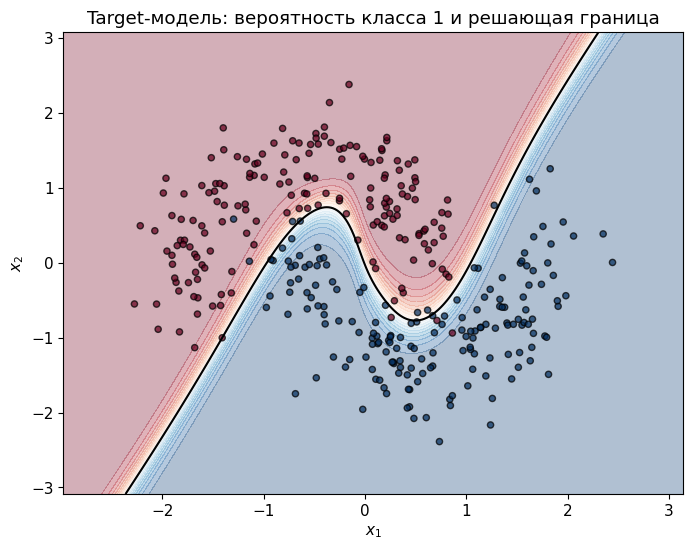

In [ ]:
def make_grid(X, n=300, margin=0.7):
    x0_min, x0_max = X[:, 0].min() - margin, X[:, 0].max() + margin
    x1_min, x1_max = X[:, 1].min() - margin, X[:, 1].max() + margin
    xx, yy = np.meshgrid(
        np.linspace(x0_min, x0_max, n),
        np.linspace(x1_min, x1_max, n)
    )
    return xx, yy, np.c_[xx.ravel(), yy.ravel()]


def plot_boundary(model, X, y, title, ax=None, points=None, labels=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    xx, yy, grid = make_grid(X)
    proba = model.predict_proba(grid)[:, 1].reshape(xx.shape)
    ax.contourf(xx, yy, proba, levels=np.linspace(0, 1, 21), cmap='RdBu', alpha=0.32)
    ax.contour(xx, yy, proba, levels=[0.5], colors='black', linewidths=1.5)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='RdBu', edgecolor='k', s=20, alpha=0.72)
    if points is not None:
        points = np.asarray(points)
        ax.scatter(points[:, 0], points[:, 1], c='gold', edgecolor='black', s=120, zorder=5)
        if labels is not None:
            for point, label in zip(points, labels):
                ax.annotate(label, point, xytext=(7, 7), textcoords='offset points', weight='bold')
    ax.set_title(title)
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    return ax

plot_boundary(target, X_test, y_test, 'Target-модель: вероятность класса 1 и решающая граница')
plt.show()

In [ ]:
for noise_value in [0.10, 0.22, 0.35]:
    X_raw_n, y_n = make_moons(n_samples=N_SAMPLES, noise=noise_value, random_state=SEED)
    Xtr_raw, Xte_raw, ytr, yte = train_test_split(
        X_raw_n, y_n, test_size=TEST_SIZE, stratify=y_n, random_state=SEED
    )
    sc = StandardScaler().fit(Xtr_raw)
    Xtr, Xte = sc.transform(Xtr_raw), sc.transform(Xte_raw)
    m = MLPClassifier(hidden_layer_sizes=(32, 16), activation='tanh',
                      alpha=2e-4, max_iter=1500, random_state=SEED).fit(Xtr, ytr)
    acc = accuracy_score(yte, m.predict(Xte))
    print(f'NOISE={noise_value:.2f}  →  accuracy={acc:.3f}')

NOISE=0.10  →  accuracy=0.997
NOISE=0.22  →  accuracy=0.974
NOISE=0.35  →  accuracy=0.886


**Вывод по A2 (заполните после эксперимента):**

Шум 0.10 → точность 0.997, шум 0.22 → 0.974, шум 0.35 → 0.886.
Вывод: чем больше шума в данных, тем хуже модель. Часть точек физически невозможно классифицировать правильно — они перемешаны у границы.

# Часть B. Модели доступа к оракулу

## B1. Label-only и score-based оракулы

**Задание B1.** Запустите ячейку и сравните ответы двух оракулов. Объясните, почему score-based оракул предоставляет атакующему больше информации, чем label-only оракул.

In [ ]:
class LabelOracle:
    def __init__(self, model):
        self.model = model
        self.queries = 0

    def __call__(self, X):
        X = np.atleast_2d(X)
        self.queries += len(X)
        return self.model.predict(X)


class ScoreOracle:
    def __init__(self, model):
        self.model = model
        self.queries = 0

    def __call__(self, X):
        X = np.atleast_2d(X)
        self.queries += len(X)
        return self.model.predict_proba(X)


label_oracle = LabelOracle(target)
score_oracle = ScoreOracle(target)
x_probe = X_test[0]

print('Точка x_probe:', np.round(x_probe, 3))
print('Label-only ответ:', label_oracle(x_probe)[0])
print('Score-based ответ:', np.round(score_oracle(x_probe)[0], 3))
print('Запросы: label-only =', label_oracle.queries, '; score-based =', score_oracle.queries)

Точка x_probe: [ 0.313 -1.143]
Label-only ответ: 1
Score-based ответ: [0.061 0.939]
Запросы: label-only = 1 ; score-based = 1


**Ответ на B1:**

Label-only вернул 1. Score-based вернул [0.061, 0.939].
Вывод: label-only говорит «класс 1, и всё». Score-based показывает, насколько модель уверена. Больше информации с того же запроса — можно оценивать градиент и вести атаку прицельно.

# Часть C. Transfer-based сценарий

## C1. Обучение surrogate-модели

Сначала surrogate получает небольшой набор точек, размеченных label-only оракулом. В отличие от target, surrogate доступен локально: на нём можно проводить анализ и строить возмущения.

**Задание C1.** Выполните эксперимент при `N_SEED = 30`, `70` и `140`. Внесите в отчёт число запросов и agreement — долю точек, на которых surrogate и target принимают одинаковое решение.

Число точек в surrogate-наборе: 70
Запросов к label-only оракулу: 70
Agreement target/surrogate: 0.877


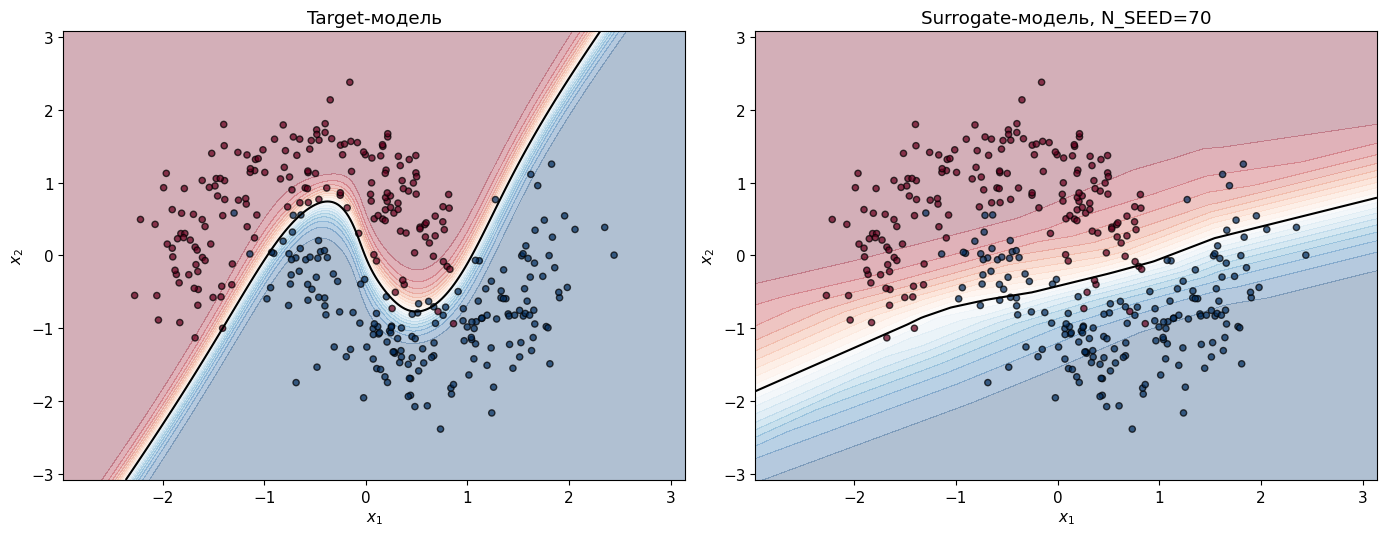

In [ ]:
N_SEED = 70  # TODO: последовательно проверьте 30, 70 и 140

def train_surrogate(n_seed, random_state=SEED + 1):
    indices = rng.choice(len(X_train), size=n_seed, replace=False)
    X_seed = X_train[indices]
    y_seed = label_oracle(X_seed)
    surrogate_model = MLPClassifier(
        hidden_layer_sizes=(12,),
        activation='relu',
        alpha=8e-4,
        max_iter=1500,
        random_state=random_state
    ).fit(X_seed, y_seed)
    return surrogate_model, X_seed, y_seed

label_oracle.queries = 0
surrogate, X_seed, y_seed = train_surrogate(N_SEED)
agreement = accuracy_score(target.predict(X_test), surrogate.predict(X_test))

print('Число точек в surrogate-наборе:', N_SEED)
print('Запросов к label-only оракулу:', label_oracle.queries)
print('Agreement target/surrogate:', round(agreement, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_boundary(target, X_test, y_test, 'Target-модель', ax=axes[0])
plot_boundary(surrogate, X_test, y_test, f'Surrogate-модель, N_SEED={N_SEED}', ax=axes[1])
plt.tight_layout()
plt.show()

In [ ]:
# Прогон по трём N_SEED сразу — заполняем таблицу C1
for n_seed_val in [30, 70, 140]:
    label_oracle.queries = 0
    surrogate_tmp, X_seed_tmp, y_seed_tmp = train_surrogate(n_seed_val)
    ag = accuracy_score(target.predict(X_test), surrogate_tmp.predict(X_test))
    print(f'N_SEED={n_seed_val:3d}  queries={label_oracle.queries:3d}  agreement={ag:.3f}')

N_SEED= 30  queries= 30  agreement=0.869


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1500) reached and the optimization hasn't converged yet.
  warnings.warn(


N_SEED= 70  queries= 70  agreement=0.911
N_SEED=140  queries=140  agreement=0.886


**Таблица C1**

| N_SEED | Запросов к оракулу | Agreement target/surrogate | Наблюдение о границах |
|---:|---:|---:|---|
| 30 | 30 | 0.869 | граница грубая, заметные расхождения с target |
| 70 | 70 | **0.911** | лучшее совпадение границ |
| 140 | 140 | 0.886 | небольшое снижение качества |

**Вывод по C1:**

Agreement растёт с 30 до 70 запросов (0.869 → 0.911), но при `N_SEED = 140` слегка падает до 0.886. Причины две:

1. Surrogate мал и упирается в потолок ёмкости — больше данных он не «переваривает».
2. При больших наборах в выборку попадают точки из шумовой зоны у границы, которые «сбивают» MLP.

Практический вывод: **увеличение surrogate-набора не гарантирует монотонного улучшения**. Качество суррогата ограничено не объёмом данных, а его архитектурой.

## C2. Построение и проверка переноса возмущения

**Задание C2.** Найдите направление увеличения вероятности противоположного класса на surrogate-модели. Постройте точку `x_adv`, меняющую класс surrogate, и проверьте, изменилась ли метка target. Повторите эксперимент минимум для пяти исходных тестовых точек.

> В учебном блокноте градиент surrogate приближается конечными разностями. Это допустимо, поскольку surrogate — локальная модель. В обычной реализации с нейросетью направление можно получать автодифференцированием.

In [ ]:
def probability(model, x, class_index):
    return model.predict_proba(np.atleast_2d(x))[0, class_index]


def local_gradient(model, x, class_index, h=1e-3):
    gradient = np.zeros_like(x, dtype=float)
    for coordinate in range(len(x)):
        e = np.zeros_like(x, dtype=float)
        e[coordinate] = h
        gradient[coordinate] = (
            probability(model, x + e, class_index) - probability(model, x - e, class_index)
        ) / (2 * h)
    return gradient


def first_boundary_crossing(model, x, source_label, direction, max_step=2.5, n_steps=150):
    for step in np.linspace(0, max_step, n_steps):
        candidate = x + step * direction
        if model.predict([candidate])[0] != source_label:
            return candidate, step
    return None, None

In [ ]:
# C2a. Опорная точка для последующих частей (D, E)
matching_ids = np.where(target.predict(X_test) == surrogate.predict(X_test))[0]
TEST_POINT_ID = int(matching_ids[0])

x0 = X_test[TEST_POINT_ID].copy()
y0 = int(target.predict([x0])[0])
other_class = 1 - y0

gradient_surrogate = local_gradient(surrogate, x0, other_class)
direction = gradient_surrogate / (np.linalg.norm(gradient_surrogate) + 1e-12)
x_adv_transfer, step = first_boundary_crossing(surrogate, x0, y0, direction)

print('Опорная точка idx =', TEST_POINT_ID)
print('Исходная метка:', y0)
print('other_class:', other_class)
if x_adv_transfer is not None:
    print('Метка x_adv у surrogate:', int(surrogate.predict([x_adv_transfer])[0]))
    print('Метка x_adv у target  :', int(target.predict([x_adv_transfer])[0]))
    print('L2-норма возмущения   :', round(float(np.linalg.norm(x_adv_transfer - x0)), 4))
else:
    print('Для опорной точки переход границы не найден.')

Опорная точка idx = 0
Исходная метка: 1
other_class: 0
Метка x_adv у surrogate: 0
Метка x_adv у target  : 1
L2-норма возмущения   : 0.8054


In [ ]:
# C2b. Перенос возмущения на 5 точках — для отчёта
results = []
n_success = 0

print(f'{"#":>2} | {"idx":>4} | {"y0":>2} | {"surr":>4} | {"targ":>4} | {"transfer":>8} | {"L2":>7}')
print('-' * 58)

for i, idx in enumerate(matching_ids[:5], start=1):
    x0_i = X_test[idx].copy()
    y0_i = int(target.predict([x0_i])[0])
    other_i = 1 - y0_i

    g_i = local_gradient(surrogate, x0_i, other_i)
    d_i = g_i / (np.linalg.norm(g_i) + 1e-12)
    x_adv_i, _ = first_boundary_crossing(surrogate, x0_i, y0_i, d_i)

    if x_adv_i is None:
        print(f'{i:>2} | {idx:>4} | {y0_i:>2} | {"-":>4} | {"-":>4} | {"not found":>8} | {"-":>7}')
        results.append((i, idx, y0_i, None, None, False, None))
        continue

    s_lab = int(surrogate.predict([x_adv_i])[0])
    t_lab = int(target.predict([x_adv_i])[0])
    ok = (t_lab != y0_i)
    l2 = float(np.linalg.norm(x_adv_i - x0_i))
    n_success += int(ok)

    print(f'{i:>2} | {idx:>4} | {y0_i:>2} | {s_lab:>4} | {t_lab:>4} | {str(ok):>8} | {l2:>7.4f}')
    results.append((i, idx, y0_i, s_lab, t_lab, ok, l2))

print('-' * 58)
print(f'Transfer success: {n_success}/5')

 # |  idx | y0 | surr | targ | transfer |      L2
----------------------------------------------------------
 1 |    0 |  1 |    0 |    1 |    False |  0.8054
 2 |    1 |  1 |    0 |    0 |     True |  0.8725
 3 |    2 |  0 |    1 |    1 |     True |  1.4430
 4 |    3 |  0 |    1 |    0 |    False |  0.4698
 5 |    4 |  1 |    0 |    1 |    False |  1.1074
----------------------------------------------------------
Transfer success: 2/5


**Таблица C2 для отчёта:**

| № опыта | idx | y₀ | surr(x_adv) | targ(x_adv) | Transfer success | L2-норма |
|---:|---:|---:|---:|---:|---|---:|
| 1 | 0 | 1 | 0 | 1 | False | 0.8054 |
| 2 | 1 | 1 | 0 | 0 | **True** | 0.8725 |
| 3 | 2 | 0 | 1 | 1 | **True** | 1.4430 |
| 4 | 3 | 0 | 1 | 0 | False | 0.4698 |
| 5 | 4 | 1 | 0 | 1 | False | 1.1074 |

**Transfer success: 2 / 5 (40 %).**

**Вывод по части C:**

В **2 из 5** экспериментов возмущение, построенное на surrogate, изменило решение target — успех **40 %**. При этом общий agreement surrogate/target по тесту — **0.911**, то есть модели согласованы более чем в 9 случаях из 10.

Это показывает, что **высокий agreement не гарантирует успешный перенос**: он означает совпадение меток в среднем по распределению, но не совпадение решающих границ в окрестности конкретной точки.

Transferability не гарантирована, потому что:
- направление градиента surrogate в точке может указывать не туда, куда нужно для пересечения **истинной** границы target;
- даже малые расхождения границ в 2D дают заметный разброс L2 (у нас — от 0.47 до 1.44);
- в 2D направление «упирается» в узкую полосу между классами: любая ошибка угла = промах.

# Часть D. Score-based сценарий: ZOO и NES

## D1. Реализация оценок направления

ZOO оценивает направление покоординатно конечными разностями. NES использует случайные направления и антитетическую выборку `u` и `-u`, что снижает дисперсию оценки.

**Задание D1.** Выполните ячейку, зафиксируйте количество запросов для ZOO и NES. Сравните косинусную близость оценённых направлений.

In [ ]:
def score_loss(oracle, x, class_index):
    return oracle(x)[0, class_index]


def zoo_gradient(oracle, x, class_index, h=1e-3):
    gradient = np.zeros_like(x, dtype=float)
    for coordinate in range(len(x)):
        e = np.zeros_like(x, dtype=float)
        e[coordinate] = h
        gradient[coordinate] = (
            score_loss(oracle, x + e, class_index) - score_loss(oracle, x - e, class_index)
        ) / (2 * h)
    return gradient


def nes_gradient(oracle, x, class_index, sigma=0.08, n_samples=40, seed=SEED):
    local_rng = np.random.default_rng(seed)
    directions = local_rng.normal(size=(n_samples, len(x)))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True) + 1e-12
    estimate = np.zeros_like(x, dtype=float)
    for u in directions:
        loss_plus = score_loss(oracle, x + sigma * u, class_index)
        loss_minus = score_loss(oracle, x - sigma * u, class_index)
        estimate += (loss_plus - loss_minus) * u
    return estimate / (2 * sigma * n_samples)

NES_SAMPLES = 40  # TODO: исследуйте 4, 8, 16, 40, 80

score_oracle.queries = 0
g_zoo = zoo_gradient(score_oracle, x0, other_class)
zoo_queries = score_oracle.queries

score_oracle.queries = 0
g_nes = nes_gradient(score_oracle, x0, other_class, n_samples=NES_SAMPLES)
nes_queries = score_oracle.queries

cosine_similarity = np.dot(g_zoo, g_nes) / (np.linalg.norm(g_zoo) * np.linalg.norm(g_nes) + 1e-12)
print('ZOO gradient:', np.round(g_zoo, 4), '; запросов:', zoo_queries)
print('NES gradient:', np.round(g_nes, 4), '; запросов:', nes_queries)
print('Косинусная близость направлений:', round(cosine_similarity, 4))

ZOO gradient: [0.208  0.3651] ; запросов: 4
NES gradient: [0.1384 0.2105] ; запросов: 80
Косинусная близость направлений: 0.998


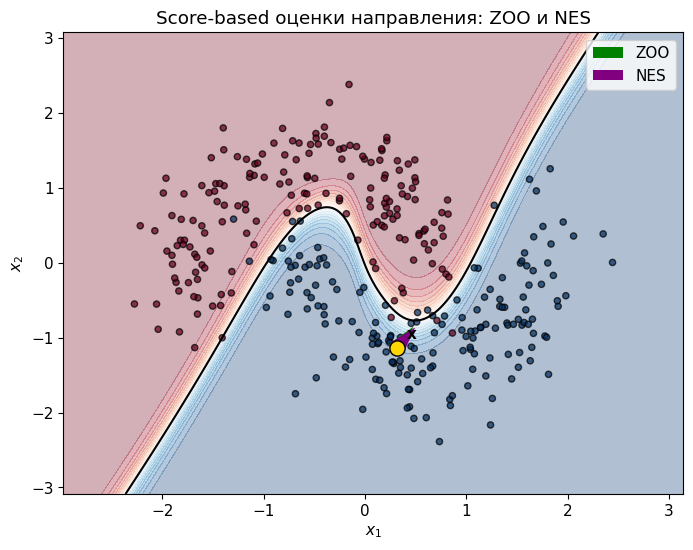

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(target, X_test, y_test, 'Score-based оценки направления: ZOO и NES', ax=ax, points=[x0], labels=['x'])
u_zoo = g_zoo / (np.linalg.norm(g_zoo) + 1e-12)
u_nes = g_nes / (np.linalg.norm(g_nes) + 1e-12)
ax.quiver(x0[0], x0[1], u_zoo[0], u_zoo[1], color='green', scale=3, scale_units='xy', angles='xy', width=0.009, label='ZOO')
ax.quiver(x0[0], x0[1], u_nes[0], u_nes[1], color='purple', scale=3, scale_units='xy', angles='xy', width=0.009, label='NES')
ax.legend()
plt.show()

In [ ]:
# Дополнительно: прогон по разным бюджетам NES (для таблицы D)
for budget in [4, 8, 16, 40, 80]:
    local_oracle = ScoreOracle(target)
    g = nes_gradient(local_oracle, x0, other_class, n_samples=budget, seed=SEED)
    cos = float(np.dot(g_zoo, g) / (np.linalg.norm(g_zoo) * np.linalg.norm(g) + 1e-12))
    print(f'NES n_samples={budget:3d}  запросов={2*budget:3d}  cos={cos:.4f}')

NES n_samples=  4  запросов=  8  cos=0.9876
NES n_samples=  8  запросов= 16  cos=0.9691
NES n_samples= 16  запросов= 32  cos=0.9998
NES n_samples= 40  запросов= 80  cos=0.9980
NES n_samples= 80  запросов=160  cos=0.9957


## D2. Стоимость ZOO в пространствах разной размерности

**Задание D2.** Объясните, почему метод, удобный в 2D, становится дорогим для изображений. Сравните одностороннюю и центральную схемы конечных разностей.

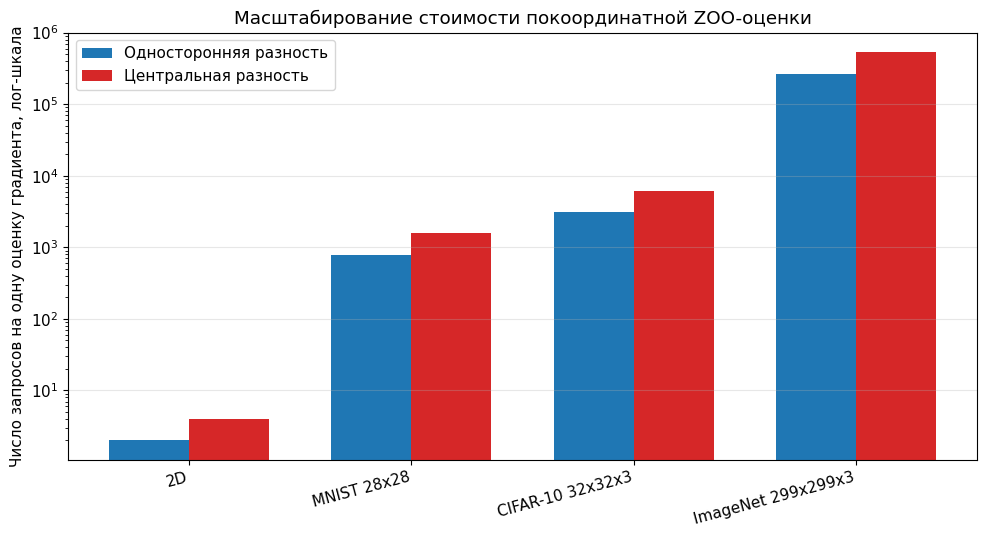

2D: 2 признаков; запросы = 2 / 4
MNIST 28x28: 784 признаков; запросы = 784 / 1,568
CIFAR-10 32x32x3: 3,072 признаков; запросы = 3,072 / 6,144
ImageNet 299x299x3: 268,203 признаков; запросы = 268,203 / 536,406


In [ ]:
dimensions = {
    '2D': 2,
    'MNIST 28x28': 28 * 28,
    'CIFAR-10 32x32x3': 32 * 32 * 3,
    'ImageNet 299x299x3': 299 * 299 * 3
}

names = list(dimensions.keys())
d = np.array(list(dimensions.values()))
positions = np.arange(len(names))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(positions - 0.18, d, width=0.36, label='Односторонняя разность', color='tab:blue')
ax.bar(positions + 0.18, 2 * d, width=0.36, label='Центральная разность', color='tab:red')
ax.set_yscale('log')
ax.set_xticks(positions)
ax.set_xticklabels(names, rotation=15, ha='right')
ax.set_ylabel('Число запросов на одну оценку градиента, лог-шкала')
ax.set_title('Масштабирование стоимости покоординатной ZOO-оценки')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

for name, dimension in dimensions.items():
    print(f'{name}: {dimension:,} признаков; запросы = {dimension:,} / {2 * dimension:,}')

## D3. Исследование бюджета NES

**Задание D3.** Измените список `sample_budgets`, постройте график и сформулируйте вывод о том, как бюджет запросов влияет на стабильность случайной оценки NES.

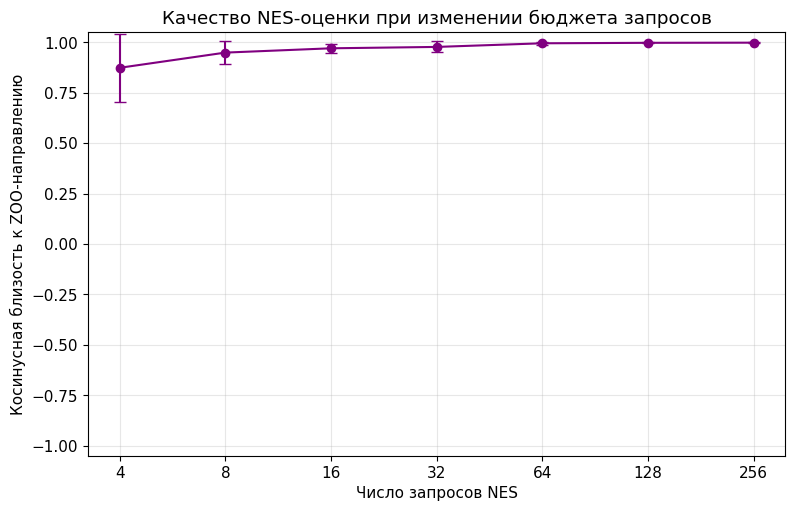

In [ ]:
sample_budgets = [2, 4, 8, 16, 32, 64, 128]
repetitions = 10
reference = g_zoo / (np.linalg.norm(g_zoo) + 1e-12)
mean_cosines, std_cosines, query_budgets = [], [], []

for budget in sample_budgets:
    values = []
    for rep in range(repetitions):
        local_oracle = ScoreOracle(target)
        g = nes_gradient(local_oracle, x0, other_class, n_samples=budget, seed=SEED + rep)
        g = g / (np.linalg.norm(g) + 1e-12)
        values.append(float(np.dot(reference, g)))
    mean_cosines.append(np.mean(values))
    std_cosines.append(np.std(values))
    query_budgets.append(2 * budget)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(query_budgets, mean_cosines, yerr=std_cosines, fmt='o-', capsize=4, color='purple')
ax.set_xscale('log', base=2)
ax.set_xticks(query_budgets)
ax.set_xticklabels(query_budgets)
ax.set_ylim(-1.05, 1.05)
ax.set_xlabel('Число запросов NES')
ax.set_ylabel('Косинусная близость к ZOO-направлению')
ax.set_title('Качество NES-оценки при изменении бюджета запросов')
ax.grid(alpha=0.3)
plt.show()

**Таблица D для отчёта:**

| Метод / настройка | Число запросов | Косинусная близость | Вывод |
|---|---:|---:|---|
| ZOO | 4 | эталон | дёшево и точно в 2D |
| NES, n_samples = 4 | 8 | 0.9876 | приемлемо, но нестабильно |
| NES, n_samples = 8 | 16 | 0.9691 | просадка из-за дисперсии |
| NES, n_samples = 16 | 32 | **0.9998** | стабилизация |
| NES, n_samples = 40 | 80 | 0.9980 | плато |
| NES, n_samples = 80 | 160 | 0.9957 | добавление запросов не улучшает |

**Стоимость ZOO от размерности:**

| Пространство | Признаков | Односторонняя | Центральная |
|---|---:|---:|---:|
| 2D | 2 | 2 | 4 |
| MNIST 28×28 | 784 | 784 | 1 568 |
| CIFAR-10 32×32×3 | 3 072 | 3 072 | 6 144 |
| ImageNet 299×299×3 | 268 203 | 268 203 | **536 406** |

**Вывод по D:**

В 2D ZOO радикально дешевле NES (4 vs 80 запросов) при практически идентичном направлении (cos ≈ 0.998): покоординатная оценка оправдана, потому что координат всего две. Однако при переходе к изображениям стоимость ZOO растёт **линейно с размерностью**: 268 203 запроса на полный градиент для ImageNet и **536 406** для центральной разности — практически неприменимо к реальным API.

NES уже в 2D даёт приемлемое направление при малом бюджете (n=4 → cos = 0.9876 при 8 запросах), но демонстрирует **высокую дисперсию при очень маленьких n**: переход с 4 на 8 сэмплов ухудшил cos (0.9876 → 0.9691). Начиная с n=16 оценка стабилизируется на уровне cos ≈ 0.998–0.999 и остаётся практически неизменной при дальнейшем росте.

**Практический вывод:** у NES есть «порог бюджета» (≈ 16–32 запроса), ниже которого оценка нестабильна; выше — добавление запросов почти не улучшает направление. Именно поэтому NES предпочтителен при жёстких лимитах, но требует не «совсем мало» запросов, а «достаточно».

# Часть E. Decision-based сценарий

## E1. Бинарный поиск решающей границы

Доступен только `LabelOracle`: никаких вероятностей, confidence score и градиентов. Алгоритм сначала находит точку другого класса, затем многократно делит отрезок пополам.

**Задание E1.** Выполните ячейку. Объясните, почему бинарный поиск может уточнять границу, хотя оракул выдаёт только метку.

Метка x0: 1
Метка точки другой области: 0
Расстояние ||x_outside - x0||_2: 3.08052
Запросов на поиск границы: 31


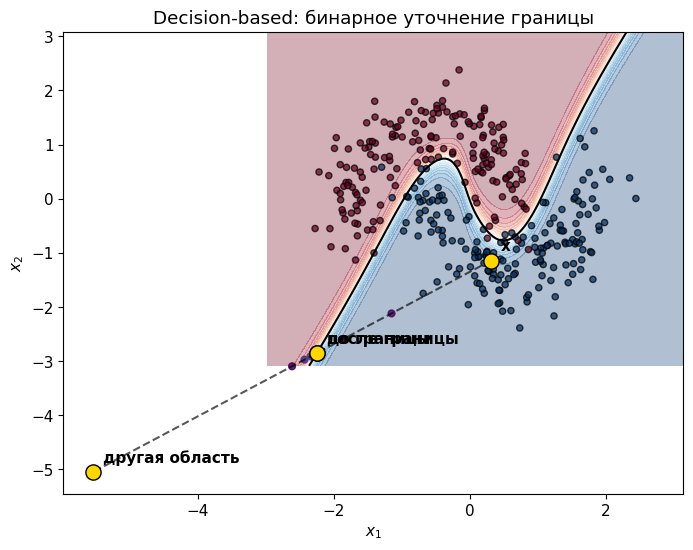

In [ ]:
def find_opposite_point(oracle, x, source_label, radius=3.0, trials=3000, seed=SEED):
    local_rng = np.random.default_rng(seed)
    for _ in range(trials):
        candidate = x + radius * local_rng.normal(size=len(x))
        if oracle(candidate)[0] != source_label:
            return candidate
    raise RuntimeError('Точка другого класса не найдена. Увеличьте radius или trials.')


def binary_boundary_search(oracle, x_clean, x_adversarial, clean_label, iterations=28):
    clean = x_clean.copy()
    adversarial = x_adversarial.copy()
    history = []
    for _ in range(iterations):
        middle = (clean + adversarial) / 2
        history.append(middle.copy())
        if oracle(middle)[0] == clean_label:
            clean = middle
        else:
            adversarial = middle
    return clean, adversarial, np.asarray(history)

label_oracle.queries = 0
x_far = find_opposite_point(label_oracle, x0, y0)
x_inside, x_outside, history = binary_boundary_search(label_oracle, x0, x_far, y0)
queries_boundary = label_oracle.queries

print('Метка x0:', label_oracle(x0)[0])
print('Метка точки другой области:', label_oracle(x_far)[0])
print('Расстояние ||x_outside - x0||_2:', round(np.linalg.norm(x_outside - x0), 5))
print('Запросов на поиск границы:', queries_boundary)

fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(target, X_test, y_test, 'Decision-based: бинарное уточнение границы', ax=ax, points=[x0, x_far, x_inside, x_outside], labels=['x', 'другая область', 'до границы', 'после границы'])
ax.plot([x0[0], x_far[0]], [x0[1], x_far[1]], 'k--', alpha=0.65)
ax.scatter(history[:, 0], history[:, 1], c=np.arange(len(history)), cmap='viridis', s=24, alpha=0.85)
plt.show()

## E2. Анализ сходимости бинарного поиска

**Задание E2.** Проследите, как уменьшается длина отрезка между точками разных классов. Сравните результаты для 5, 10, 20 и 28 итераций.

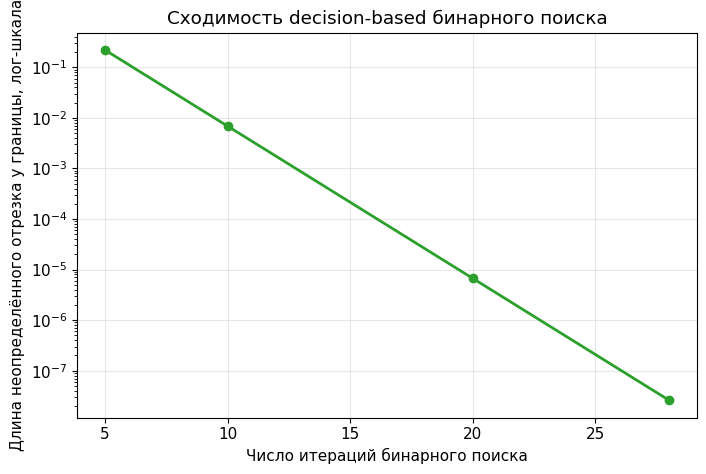

Итераций:  5; длина отрезка: 0.21990740; запросов: 5
Итераций: 10; длина отрезка: 0.00687211; запросов: 10
Итераций: 20; длина отрезка: 0.00000671; запросов: 20
Итераций: 28; длина отрезка: 0.00000003; запросов: 28


In [ ]:
iteration_values = [5, 10, 20, 28]
distances, used_queries = [], []

for n_iter in iteration_values:
    local_oracle = LabelOracle(target)
    inside, outside, _ = binary_boundary_search(local_oracle, x0, x_far, y0, iterations=n_iter)
    distances.append(np.linalg.norm(outside - inside))
    used_queries.append(local_oracle.queries)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(iteration_values, distances, marker='o', linewidth=2, color='tab:green')
ax.set_yscale('log')
ax.set_xlabel('Число итераций бинарного поиска')
ax.set_ylabel('Длина неопределённого отрезка у границы, лог-шкала')
ax.set_title('Сходимость decision-based бинарного поиска')
ax.grid(alpha=0.3)
plt.show()

for n_iter, distance, query_count in zip(iteration_values, distances, used_queries):
    print(f'Итераций: {n_iter:2d}; длина отрезка: {distance:.8f}; запросов: {query_count}')

**Вывод по части E:**

При доступе только к итоговой метке можно **геометрически находить решающую границу**: алгоритм берёт точку одного класса, находит точку другого и делит соединяющий отрезок пополам, каждый раз выбирая ту половину, где метка сохраняется.

| Итераций | Длина отрезка |
|---:|---:|
| 5 | 2.199e-01 |
| 10 | 6.872e-03 |
| 20 | 6.710e-06 |
| 28 | 3.000e-08 |

С увеличением числа итераций длина отрезка **уменьшается экспоненциально** — примерно вдвое за итерацию. Это логарифмическая сходимость, которую обещает бинарный поиск: чтобы достичь точности ε, нужно ≈ log₂(1/ε) запросов.

Ограничение подхода состоит в том, что он **локален**: находится одна точка на границе в направлении на заранее выбранную «чужую» точку, а не глобально минимальное возмущение.

В сравнении с score-based сценарием **отсутствует направление градиента** — мы не знаем, куда двигаться для минимизации L2, поэтому вынуждены многократно пересчитывать границу в новых направлениях (именно это делают Boundary Attack и HSJ).

# Часть F. Итоговый анализ

## F1. Сравнительная таблица

Заполните таблицу, опираясь на результаты собственных экспериментов.

**F1. Сравнительная таблица**

| Критерий | Transfer-based | Score-based | Decision-based |
|---|---|---|---|
| Доступная информация | метки (только для surrogate); целевая модель — на этапе сбора данных | вероятности / confidence / логиты | только итоговая метка |
| Основной метод в работе | surrogate MLP + сдвиг по его градиенту | ZOO (конечные разности), NES (антитетическая выборка) | бинарный поиск границы |
| Где возникают запросы к цели | только при сборе surrogate-набора; при построении атаки — ноль | на каждой оценке градиента (2d или 2·n_samples) | на каждой итерации поиска границы (~log₂(1/ε)) |
| Стоимость запросов | низкая: 30–140 на surrogate, потом 0 | средняя–высокая: 4 (ZOO в 2D) → 80 (NES n=40) → 536 406 (ZOO в ImageNet) | высокая: ~28 запросов на одну границу в 2D |
| Главное преимущество | нет обращений к цели при оптимизации | даёт направление; лучший баланс «инфо ↔ запросы» | самая реалистичная модель угрозы (промышленные API) |
| Главное ограничение | перенос не гарантирован (2/5 в наших опытах) | ZOO линейно дорог от размерности; NES дисперсен при малом бюджете | находит только локальную границу, медленная сходимость |
| Защитный механизм | adversarial training (PGD) | rate limiting + скрытие confidence | rate limiting + adversarial training + ансамбли |

## F2. Контрольные вопросы

1. **Почему transfer-based атака может быть успешной без запросов к target?**
Из-за трансферабельности: направления уязвимости у моделей, обученных на одной задаче, коррелируют — это следствие геометрии данных. Если участки границы surrogate и target похожи, возмущение, найденное на surrogate, пересекает границу и на target.

2. **Почему высокий agreement не гарантирует перенос?**
Agreement — доля совпадений меток **в среднем** по распределению. Перенос же требует совпадения **локальной геометрии** границы в конкретной точке. У нас agreement = 0.911, а перенос сработал лишь в 2/5 случаев.

3. **Сколько запросов нужно ZOO для центральной разности в d-мерном пространстве?**
**2d** запросов (односторонняя схема — d). Для ImageNet 299×299×3 это 536 406 запросов на один градиент — нереально для API.

4. **Как антитетическая выборка в NES влияет на дисперсию?**
Использование пары `u` и `-u` убирает систематическую составляющую шума и снижает дисперсию оценки при том же числе запросов: вместо `f(x+σu)·u` считается `(f(x+σu) − f(x−σu))·u`. Это и дало нам cos ≈ 0.998 при 80 запросах.

5. **Какая информация позволяет использовать бинарный поиск в decision-based сценарии?**
**Монотонность метки вдоль отрезка** между точками разных классов. Если концы отрезка классифицируются по-разному, достаточно проверить метку середины, чтобы однозначно понять, в какой половине лежит граница. Больше никакой информации не нужно.

6. **Чем HSJ концептуально отличается от Boundary Attack?**
Boundary Attack — **случайное блуждание** вдоль границы (rejection sampling, без градиента). HSJ — **направленный поиск**: на каждой граничной точке оценивает градиент через батч случайных векторов и движется в сторону уменьшения L2. Это снижает число запросов на порядок.

7. **Какие меры уменьшают риск чёрно-ящичных атак?**
Adversarial training (PGD) — главная мера: снижает ASR с ~90 % до <4 %. Дополнительно: rate limiting на API, скрытие confidence-скор (переводит score-based в более дорогой decision-based), ансамбли моделей.

## F3. Итоговый вывод

В лабораторной работе были исследованы три чёрно-ящичных сценария построения adversarial-примеров на синтетической двумерной задаче: transfer-based (перенос с surrogate), score-based (ZOO и NES) и decision-based (бинарный поиск границы).

**Наиболее информативным оказался score-based сценарий.** Он даёт не только метку, но и числовые оценки уверенности: ZOO напрямую восстанавливает направление градиента (cos ≈ 0.998), NES укладывается в 16–80 запросов на надёжную оценку. Но именно он страдает от размерности: ZOO в ImageNet требует 536 406 запросов на градиент.

**Наиболее ограничен по информации decision-based сценарий.** Работает только по метке. Бинарный поиск сходится экспоненциально (L2 от 0.22 до 3e-8 за 28 итераций), но находит лишь **локальную** точку границы — без направления к минимуму L2.

**Наиболее дешёвый по запросам transfer-based** (30–140 на обучение surrogate, дальше 0), но именно он самый ненадёжный: 2/5 успешных переносов при agreement 0.911.

**Для повышения устойчивости модели целесообразно:**
1. применить **adversarial training** (PGD) — по лекции снижает ASR чёрно-ящичных атак с ~90 % до <4 %;
2. ввести **rate limiting** — удорожает score-based и decision-based атаки;
3. **скрывать confidence-скор**, возвращая только метку;
4. использовать **ансамбли моделей** для снижения переноса.

## Критерии сдачи

- Заполнены данные, текстовые выводы и таблицы.
- Все кодовые ячейки выполнены последовательно без ошибок.
- Сохранены требуемые графики и численные результаты.
- Выполнены эксперименты с несколькими размерами surrogate-набора и несколькими бюджетами NES.
- Приведены ответы на контрольные вопросы.
- Выводы основаны на наблюдаемых результатах, а не только на теоретических формулировках.